In [1]:
import gdsfactory as gf

from pdk.tfln.pdk import TFLN_PDK
from pdk.tfln.constants import CONSTANTS
from pdk.tfln.cells.directional_coupler import directional_coupler
from pdk.tfln.cells.grating_coupler import grating_coupler

CONSTANTS

/home/angel/Code/pdk_demo/pdk_demo/.venv/lib/python3.12/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='layer_views', input_value=<LAYER.WG: 1>, input_type=LAYER])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='layer_views', input_value=<LAYER.MET1: 47>, input_type=LAYER])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='layer_views', input_value=<LAYER.MET2: 48>, input_type=LAYER])
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='layer_views', input_value=<LAYER.VIA: 49>, input_type=LAYER])
  return self.__pydantic_serializer__.to_python(


{'wg_width': 1.0,
 'wg_radius': 50.0,
 'ridge_height': 0.4,
 'slab_thickness': 0.2,
 'sidewall_angle': 70.0,
 's_bend_length': 20.0,
 'dc_port_separation': 4.0,
 'dc_gap': 0.4,
 'dc_length': 21.0,
 'taper_width_wide': 12.0,
 'taper_length': 200.0,
 'gc_period': 0.95,
 'gc_fill': 0.6,
 'gc_n_periods': 20.0,
 'gc_fiber_angle': 8.0}

In [6]:
dc = directional_coupler()
gc = grating_coupler()
wg = gf.components.straight(length=100, cross_section="wg")
gc.info

Info(period=0.95, fill=0.6, n_periods=20, fiber_angle=8, grating_length=19)

In [7]:
c = gf.Component()
gc_ref = c << gc
gc_ref.mirror_x()                         # grating on the left, o1 facing right
wg_ref = c << wg
dc_ref = c << dc

wg_ref.connect("o1", gc_ref.ports["o1"])    # taper narrow end -> straight
dc_ref.connect("o1", wg_ref.ports["o2"])    # straight -> coupler input

c.add_port("fiber", port=gc_ref.ports["fiber"])
for name in ("o2", "o3", "o4"):
    c.add_port(name, port=dc_ref.ports[name])

for p in c.ports:
    print(p.name, p.center, p.orientation, p.width)

fiber (-209.5, 0.0) 90.0 10.4
o2 (100.0, 4.0) 180.0 1.0
o3 (161.0, 4.0) 0.0 1.0
o4 (161.0, 0.0) 0.0 1.0


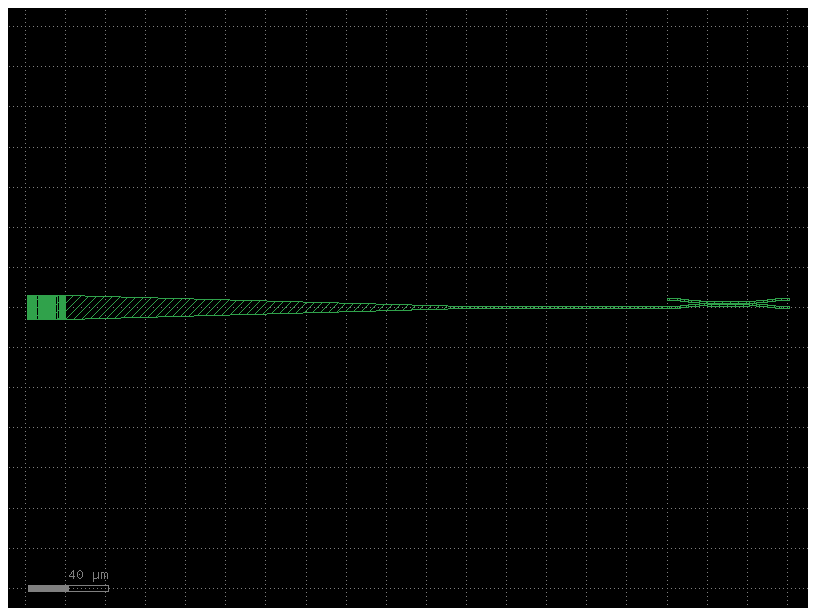

In [8]:
c.plot()